In [ ]:
import pandas as pd
df = pd.read_csv("../Task1_Data_Cleaning/cleaned_superstore.csv")
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [ ]:
df.describe()

,Row ID,Order Date,Ship Date,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994,9994,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,2016-04-30 00:07:12.259355648,2016-05-03 23:06:58.571142912,55190.379428,229.858001,3.789574,0.156203,28.656896
min,1.000000,2014-01-03 00:00:00,2014-01-07 00:00:00,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,2015-05-23 00:00:00,2015-05-27 00:00:00,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,2016-06-26 00:00:00,2016-06-29 00:00:00,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,2017-05-14 00:00:00,2017-05-18 00:00:00,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,2017-12-30 00:00:00,2018-01-05 00:00:00,99301.000000,22638.480000,14.000000,0.800000,8399.976000
std,2885.163629,NaN,NaN,32063.693350,623.245101,2.225110,0.206452,234.260108


In [3]:
# Calculate total sales and profit for each product category
category_summary = df.groupby("Category")[["Sales", "Profit"]].sum()

# Display the results
category_summary

,Sales,Profit
Category,,
Furniture,741999.7953,18451.2728
Office Supplies,719047.0320,122490.8008
Technology,836154.0330,145454.9481


In [ ]:
# Sales and Profit by Region
# Calculate total sales and profit for each region
region_summary = df.groupby("Region")[["Sales", "Profit"]].sum()
# Display the results
region_summary

,Sales,Profit
Region,,
Central,501239.8908,39706.3625
East,678781.2400,91522.7800
South,391721.9050,46749.4303
West,725457.8245,108418.4489


In [ ]:
# Top 10 Best-Selling Products
# Group products and calculate their total sales
product_sales = df.groupby("Product Name")["Sales"].sum()
# Sort sales from highest to lowest and select the top 10 products
top_products = product_sales.sort_values(ascending=False).head(10)
# Display the top 10 products
top_products

Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64

In [ ]:
# Top 10 Most Profitable Products
# Group products and calculate their total profit
product_profit = df.groupby("Product Name")["Profit"].sum()
# Sort profit from highest to lowest and select the top 10
top_profitable_products = product_profit.sort_values(ascending=False).head(10)
# Display the top 10 most profitable products
top_profitable_products

Product Name
Canon imageCLASS 2200 Advanced Copier                                          25199.9280
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind     7753.0390
Hewlett Packard LaserJet 3310 Copier                                            6983.8836
Canon PC1060 Personal Laser Copier                                              4570.9347
HP Designjet T520 Inkjet Large Format Printer - 24" Color                       4094.9766
Ativa V4110MDD Micro-Cut Shredder                                               3772.9461
3D Systems Cube Printer, 2nd Generation, Magenta                                3717.9714
Plantronics Savi W720 Multi-Device Wireless Headset System                      3696.2820
Ibico EPK-21 Electric Binding System                                            3345.2823
Zebra ZM400 Thermal Label Printer                                               3343.5360
Name: Profit, dtype: float64

In [ ]:
# Sales by Customer Segment
# Group records by customer segment and calculate total sales
segment_sales = df.groupby("Segment")["Sales"].sum()
# Sort sales from highest to lowest
segment_sales = segment_sales.sort_values(ascending=False)
# Display the results
segment_sales

Segment
Consumer       1.161401e+06
Corporate      7.061464e+05
Home Office    4.296531e+05
Name: Sales, dtype: float64

In [ ]:
# Profit by Customer Segment
# Calculate total profit for each customer segment
segment_profit = df.groupby("Segment")["Profit"].sum()
# Sort profit from highest to lowest
segment_profit = segment_profit.sort_values(ascending=False)
# Display the results
segment_profit

Segment
Consumer       134119.2092
Corporate       91979.1340
Home Office     60298.6785
Name: Profit, dtype: float64

In [ ]:
# Sales and Profit by Ship Mode
# # Calculate total sales and profit for each shipping method
ship_mode_summary = df.groupby("Ship Mode")[["Sales", "Profit"]].sum()
# Display the results
ship_mode_summary

,Sales,Profit
Ship Mode,,
First Class,3.514284e+05,48969.8399
Same Day,1.283631e+05,15891.7589
Second Class,4.591936e+05,57446.6354
Standard Class,1.358216e+06,164088.7875


In [ ]:
# Monthly Sales Trend
# # Extract the year and month from each order date
df["Year-Month"] = df["Order Date"].dt.to_period("M")
# Calculate total sales for each month
monthly_sales = df.groupby("Year-Month")["Sales"].sum()
# Display the monthly sales
monthly_sales

Year-Month
2014-01     14236.8950
2014-02      4519.8920
2014-03     55691.0090
2014-04     28295.3450
2014-05     23648.2870
2014-06     34595.1276
2014-07     33946.3930
2014-08     27909.4685
2014-09     81777.3508
2014-10     31453.3930
2014-11     78628.7167
2014-12     69545.6205
2015-01     18174.0756
2015-02     11951.4110
2015-03     38726.2520
2015-04     34195.2085
2015-05     30131.6865
2015-06     24797.2920
2015-07     28765.3250
2015-08     36898.3322
2015-09     64595.9180
2015-10     31404.9235
2015-11     75972.5635
2015-12     74919.5212
2016-01     18542.4910
2016-02     22978.8150
2016-03     51715.8750
2016-04     38750.0390
2016-05     56987.7280
2016-06     40344.5340
2016-07     39261.9630
2016-08     31115.3743
2016-09     73410.0249
2016-10     59687.7450
2016-11     79411.9658
2016-12     96999.0430
2017-01     43971.3740
2017-02     20301.1334
2017-03     58872.3528
2017-04     36521.5361
2017-05     44261.1102
2017-06     52981.7257
2017-07     45264.4160


In [ ]:
# Find the month with the highest sales
print("Highest sales month:")
print(monthly_sales.idxmax(), monthly_sales.max())
# Find the month with the lowest sales
print("\nLowest sales month:")
print(monthly_sales.idxmin(), monthly_sales.min())

Highest sales month:
2017-11 118447.825

Lowest sales month:
2014-02 4519.892


In [ ]:
# Calculate total sales for each sub-category
subcategory_sales = df.groupby("Sub-Category")["Sales"].sum()
# Sort from highest sales to lowest
subcategory_sales = subcategory_sales.sort_values(ascending=False)
# Display the results
subcategory_sales

Sub-Category
Phones         330007.0540
Chairs         328449.1030
Storage        223843.6080
Tables         206965.5320
Binders        203412.7330
Machines       189238.6310
Accessories    167380.3180
Copiers        149528.0300
Bookcases      114879.9963
Appliances     107532.1610
Furnishings     91705.1640
Paper           78479.2060
Supplies        46673.5380
Art             27118.7920
Envelopes       16476.4020
Labels          12486.3120
Fasteners        3024.2800
Name: Sales, dtype: float64

In [13]:
# Calculate total profit for each sub-category
subcategory_profit = df.groupby("Sub-Category")["Profit"].sum()

# Find the sub-category with the highest profit
print("Highest profit:")
print(subcategory_profit.idxmax(), subcategory_profit.max())

# Find the sub-category with the lowest profit
print("\nLowest profit:")
print(subcategory_profit.idxmin(), subcategory_profit.min())

Highest profit:
Copiers 55617.8249

Lowest profit:
Tables -17725.4811


In [14]:
state_sales = df.groupby("State")["Sales"].sum()
state_sales = state_sales.sort_values(ascending=False)

state_sales.head(10)

State
California      457687.6315
New York        310876.2710
Texas           170188.0458
Washington      138641.2700
Pennsylvania    116511.9140
Florida          89473.7080
Illinois         80166.1010
Ohio             78258.1360
Michigan         76269.6140
Virginia         70636.7200
Name: Sales, dtype: float64

In [15]:
state_profit = df.groupby("State")["Profit"].sum()
state_profit = state_profit.sort_values(ascending=False)

state_profit.head(10)


State
California    76381.3871
New York      74038.5486
Washington    33402.6517
Michigan      24463.1876
Virginia      18597.9504
Indiana       18382.9363
Georgia       16250.0433
Kentucky      11199.6966
Minnesota     10823.1874
Delaware       9977.3748
Name: Profit, dtype: float64

In [16]:
category_profit = df.groupby("Category")["Profit"].sum()

category_profit

Category
Furniture           18451.2728
Office Supplies    122490.8008
Technology         145454.9481
Name: Profit, dtype: float64

In [17]:
discount_summary = df.groupby("Discount")[["Sales", "Profit"]].sum()

discount_summary

,Sales,Profit
Discount,,
0.00,1.087908e+06,320987.6032
0.10,5.436935e+04,9029.1770
0.15,2.755852e+04,1418.9915
0.20,7.645944e+05,90337.3060
0.30,1.032267e+05,-10369.2774
0.32,1.449346e+04,-2391.1377
0.40,1.164178e+05,-23057.0504
0.45,5.484974e+03,-2493.1111
0.50,5.891854e+04,-20506.4281


In [18]:
quantity_summary = df.groupby("Category")["Quantity"].sum()

quantity_summary

Category
Furniture           8028
Office Supplies    22906
Technology          6939
Name: Quantity, dtype: int64

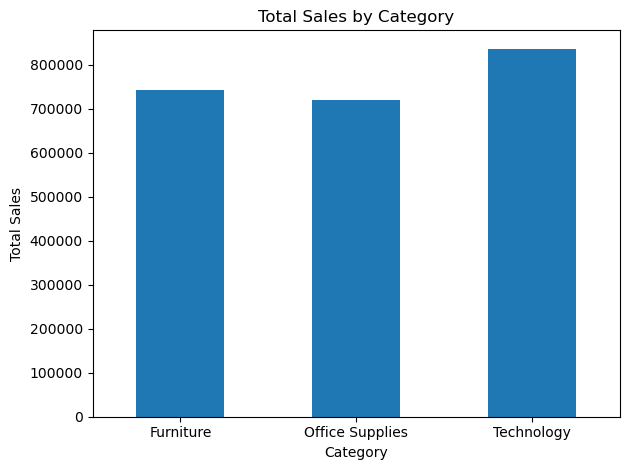

In [21]:
category_sales = df.groupby("Category")["Sales"].sum()

category_sales.plot(kind="bar", title="Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [20]:
import matplotlib.pyplot as plt

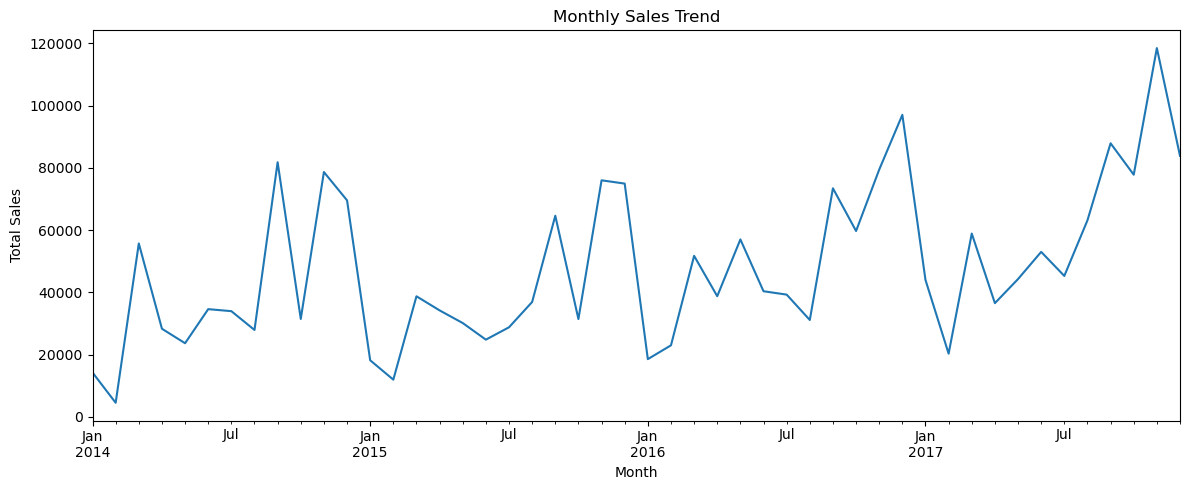

In [22]:
monthly_sales.plot(kind="line", title="Monthly Sales Trend", figsize=(12, 5))
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()